# Numero di cammini — plot

N_k(p) = numero di cammini di lunghezza k in C che arrivano nel prodotto p (N_1 = numero di input).
Legge `results/numero_cammini/cammini_per_product/{C_TYPE}/cammini_per_product_{res}_digits.parquet`,
prodotti da `notebooks/data_generation/numero_cammini.ipynb`.

1. ⟨N_k⟩ (media sui prodotti) al variare di k, scala log
2. correlazione fra N_1 e N_k al variare di k (colore = risoluzione, linea piena = Pearson, tratteggiata = Spearman)

Queste grandezze dipendono solo da C, non dall'algoritmo.
Figure in PDF in `figures/numero_cammini/{C_TYPE}/`.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = next(p for p in [Path().resolve(), *Path().resolve().parents] if (p / "src").is_dir())
sys.path.insert(0, str(ROOT))

from src.plotting import (set_style, figsize, save_fig, two_part_legend, common_ylim,
                          SINGLE, HALF, PALETTE, RES_MARKER, SEQ_CMAP, SYMBOLS)
from src.plotting import load_stability, check_eta0, plot_stability, plot_corr_vs_order

set_style()

## Configurazione

In [2]:
C_TYPE = "C_classica"            # "C_classica" | "C_nilpotente"
RESOLUTIONS = [4, 6]
K_MAX = None                     # None = tutti gli ordini disponibili (9 per C classica, 49 per C nilpotente)
SHOW_RHO_K = C_TYPE == "C_classica"   # retta di riferimento rho^k (per C nilpotente rho = 0)

DATA_DIR = ROOT / "results" / "numero_cammini" / "cammini_per_product" / C_TYPE
SAVE_FIGS = True
FIG_DIR = ROOT / "plots" / "numero_cammini" / C_TYPE

## Caricamento

In [3]:
def load_cammini(res):
    df = pd.read_parquet(DATA_DIR / f"cammini_per_product_{res}_digits.parquet").set_index("prodotto")
    df.columns = [int(c.rsplit("_", 1)[1]) for c in df.columns]      # numero_input_ordine_k -> k
    return df if K_MAX is None else df.loc[:, :K_MAX]

cammini = {res: load_cammini(res) for res in RESOLUTIONS}
for res, df in cammini.items():
    print(f"{res} digits: {df.shape[0]} prodotti, ordini k = 1..{df.columns.max()}")

4 digits: 1205 prodotti, ordini k = 1..9
6 digits: 5079 prodotti, ordini k = 1..9


## Plot 1 — numero medio di cammini entranti ⟨N_k⟩ al variare di k

Con `SHOW_RHO_K` si aggiunge, per ogni risoluzione, la retta ρ^k (ρ = autovalore principale di C classica),
senza alcun fit: mostra che la crescita dei cammini è governata da ρ.

In [4]:
from src.C_properties import autovettore_and_autovalore_principale

def rho_C(res):
    """Autovalore principale della C classica alla risoluzione data."""
    C = pd.read_parquet(ROOT / "data" / "HS02_all_years" / f"{res}_digits" / "alligned" / "binarized"
                        / "C" / f"C_{res}_digits_HS02.parquet")
    rho, _ = autovettore_and_autovalore_principale(C.T)
    return float(np.real(rho))

rho = {res: rho_C(res) for res in RESOLUTIONS} if SHOW_RHO_K else {}
for res in rho:
    m = cammini[res].mean()
    ratio = m / rho[res] ** m.index.to_numpy()
    print(f"{res} digits: rho = {rho[res]:.2f},  <N_k>/rho^k per k = 1..{m.index.max()}: "
          + ", ".join(f"{r:.2f}" for r in ratio))

4 digits: rho = 34.68,  <N_k>/rho^k per k = 1..9: 0.96, 0.88, 0.82, 0.78, 0.77, 0.75, 0.75, 0.74, 0.74
6 digits: rho = 94.39,  <N_k>/rho^k per k = 1..9: 0.90, 0.84, 0.76, 0.73, 0.72, 0.72, 0.71, 0.71, 0.71


'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp


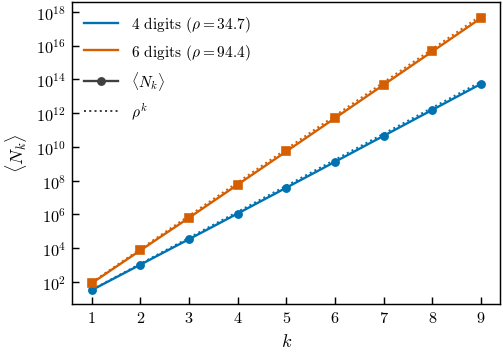

In [5]:
def plot_numero_medio(cammini):
    fig, ax = plt.subplots(figsize=figsize(*SINGLE))
    many = max(df.shape[1] for df in cammini.values()) > 15
    for res, df in cammini.items():
        m = df.mean()
        m = m[m > 0]                              # in scala log gli zeri non si possono disegnare
        ax.plot(m.index, m.values, ls="none", marker=RES_MARKER[res], ms=2.5 if many else 4,
                color=PALETTE[res])
        if res in rho:
            k = np.linspace(m.index.min(), m.index.max(), 200)
            ax.plot(k, rho[res] ** k, ls=":", lw=1.1, color=PALETTE[res], zorder=0)
    ax.set_yscale("log")
    ax.set_xlabel(r"$k$")
    ax.set_ylabel(r"$\langle N_k \rangle$")
    if not many:
        ax.set_xticks(m.index)
    res_items = [(f"{r} digits" + (rf" ($\rho = {rho[r]:.1f}$)" if r in rho else ""), PALETTE[r]) for r in cammini]
    if rho:
        handles = [plt.Line2D([], [], ls="none", marker=RES_MARKER[r], color=c) for r, (_, c) in zip(cammini, res_items)]
        handles += [plt.Line2D([], [], ls="none", color="0.25", marker="o", ms=4),
                    plt.Line2D([], [], color="0.25", ls=":", lw=1.1)]
        labels = [l for l, _ in res_items] + [r"$\langle N_k \rangle$", r"$\rho^k$"]
        ax.legend(handles, labels, loc="upper left")
    else:
        ax.legend([plt.Line2D([], [], ls="none", color=c, marker=RES_MARKER[r], ms=4) for r, (_, c) in zip(cammini, res_items)],
                  [l for l, _ in res_items], loc="upper left")
    fig.tight_layout()
    if SAVE_FIGS:
        save_fig(fig, FIG_DIR / "numero_medio_cammini")
    plt.show()

plot_numero_medio(cammini)

## Plot 2 — correlazione fra numero di input (N_1) e cammini di ordine k

'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp


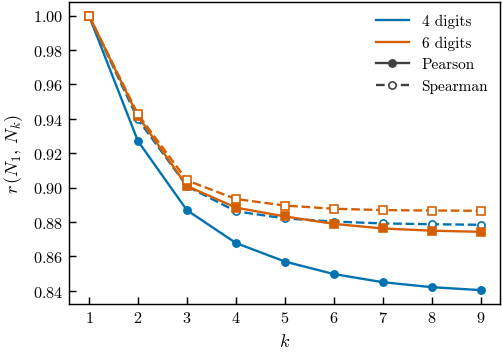

In [6]:
def corr_ordine1(df):
    return pd.DataFrame({m: df.corrwith(df[1], method=m) for m in ("pearson", "spearman")})

def plot_corr_ordine1(cammini):
    fig, ax = plt.subplots(figsize=figsize(*SINGLE))
    many = max(df.shape[1] for df in cammini.values()) > 15
    for res, df in cammini.items():
        corr = corr_ordine1(df)
        c = PALETTE[res]
        for m, ls, filled in (("pearson", "-", True), ("spearman", "--", False)):
            ax.plot(corr.index, corr[m], ls="none", marker=RES_MARKER[res], ms=2.5 if many else 4,
                    color=c, mfc=c if filled else "white", mec=c)
    ax.set_xlabel(r"$k$")
    ax.set_ylabel(r"$r\,(N_1,\, N_k)$")
    if not many:
        ax.set_xticks(corr.index)
    two_part_legend(ax, [(f"{r} digits", PALETTE[r], RES_MARKER[r]) for r in cammini],
                    [("Pearson", "-", True), ("Spearman", "--", False)], discrete=True,
                    handlelength=1.0, loc="best")
    fig.tight_layout()
    if SAVE_FIGS:
        save_fig(fig, FIG_DIR / "corr_ordine1_ordinek")
    plt.show()

plot_corr_ordine1(cammini)